#  Text2Image-GAN — CLIP-Guided Conditional Image Generation (v2)

| Component | Detail |
|---|---|
| **Text Encoder** | Frozen CLIP ViT-B/32 → 512-d embedding |
| **Generator** | Noise + text → Upsample+Conv2d stack → 64×64 RGB (no checkerboard) |
| **Discriminator** | CNN + text projection + mismatch negatives + label smoothing |
| **Generator Loss** | L_G = L_adv + λ·L_CLIP (semantic alignment) |
| **Split** | Image-level 80/10/10 train/val/test (zero caption leakage) |
| **Evaluation** | CLIPScore by category · Failure analysis · Diversity test |
| **Hardware** | Apple M2 MPS · CUDA · CPU (auto-detected) |


In [34]:
# ── 1. Install dependencies ───────────────────────────────────────────────────
import sys, subprocess

def pip(*args):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *args])

try:
    import torch
    print(f"✅ PyTorch {torch.__version__} already installed")
except ImportError:
    pip("torch", "torchvision")

pip("ftfy", "regex", "tqdm", "Pillow", "matplotlib", "pandas", "scikit-learn", "kaggle")

try:
    import clip
    print("✅ CLIP already installed")
except ImportError:
    pip("clip @ git+https://github.com/openai/CLIP.git")

print("✅ All dependencies ready")


✅ PyTorch 2.12.0 already installed
✅ CLIP already installed
✅ All dependencies ready



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [35]:
# ── 2. Imports & Hardware Detection ──────────────────────────────────────────
import os, random, math, time, json, csv
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.utils as vutils
from sklearn.model_selection import train_test_split

import clip

# ── Device: MPS (M2) → CUDA → CPU ────────────────────────────────────────────
def get_device():
    if torch.backends.mps.is_available() and torch.backends.mps.is_built():
        return torch.device("mps"), "Apple M2 MPS 🍎"
    elif torch.cuda.is_available():
        p = torch.cuda.get_device_properties(0)
        return torch.device("cuda"), f"CUDA — {p.name} ({p.total_memory//1024**2} MB) ⚡"
    return torch.device("cpu"), "CPU 🖥️"

DEVICE, DEVICE_LABEL = get_device()
print(f"🔧 Device: {DEVICE_LABEL}")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ── Config ────────────────────────────────────────────────────────────────────
CFG = dict(
    IMG_SIZE    = 64,
    LATENT_DIM  = 100,
    TEXT_DIM    = 512,
    EMBED_DIM   = 256,
    GEN_FEAT    = 64,
    DIS_FEAT    = 64,
    BATCH_SIZE  = 64,
    LR_G        = 1e-4,
    LR_D        = 1e-4,
    BETA1       = 0.5,
    BETA2       = 0.999,
    EPOCHS      = 40,
    SAVE_EVERY  = 5,
    NUM_WORKERS = 0,
    MAX_SAMPLES = 8000,
    LAMBDA_CLIP = 0.5,   # weight for CLIP alignment loss in generator
)
print("✅ Config loaded")
print(f"   LAMBDA_CLIP={CFG['LAMBDA_CLIP']} | EPOCHS={CFG['EPOCHS']} | IMG={CFG['IMG_SIZE']}x{CFG['IMG_SIZE']}")


🔧 Device: Apple M2 MPS 🍎
✅ Config loaded
   LAMBDA_CLIP=0.5 | EPOCHS=40 | IMG=64x64


In [36]:
# ── 3. Dataset Download + Image-Level Train/Val/Test Split ────────────────────
import shutil

DATA_DIR  = Path("flickr8k")
IMG_DIR   = DATA_DIR / "Images"
CAPS_FILE = DATA_DIR / "captions.txt"

def download_flickr8k_kaggle():
    try:
        import kaggle
        kaggle.api.authenticate()
        kaggle.api.dataset_download_files(
            "adityajn105/flickr8k", path=str(DATA_DIR), unzip=True)
        for p in DATA_DIR.rglob("captions.txt"):
            shutil.copy(p, CAPS_FILE)
        print("✅ Flickr8k downloaded via Kaggle")
        return True
    except Exception as e:
        print(f"⚠️  Kaggle download failed: {e}")
        return False

if not CAPS_FILE.exists():
    print("📥 Attempting Kaggle download…")
    if not download_flickr8k_kaggle():
        raise RuntimeError(
            "Dataset not found. Run manually:\n"
            "  kaggle datasets download -d adityajn105/flickr8k --path ./flickr8k --unzip"
        )
else:
    print("✅ Dataset already present")

# ── Normalise columns ─────────────────────────────────────────────────────────
df_caps = pd.read_csv(CAPS_FILE)
df_caps.columns = [c.strip().lower() for c in df_caps.columns]
if "file_name" in df_caps.columns: df_caps.rename(columns={"file_name": "image"},   inplace=True)
if "comment"   in df_caps.columns: df_caps.rename(columns={"comment":   "caption"}, inplace=True)

df_caps = df_caps.drop_duplicates(subset="image").reset_index(drop=True)
df_caps = df_caps[df_caps["image"].apply(lambda f: (IMG_DIR / f).exists())]
df_caps = df_caps.head(CFG["MAX_SAMPLES"]).reset_index(drop=True)
print(f"📊 Total usable pairs: {len(df_caps)}")

# ── IMAGE-LEVEL split — prevents caption leakage ──────────────────────────────
unique_imgs             = df_caps["image"].unique()
train_imgs, temp_imgs   = train_test_split(unique_imgs, test_size=0.20, random_state=SEED)
val_imgs,   test_imgs   = train_test_split(temp_imgs,   test_size=0.50, random_state=SEED)

df_train = df_caps[df_caps["image"].isin(train_imgs)].reset_index(drop=True)
df_val   = df_caps[df_caps["image"].isin(val_imgs)].reset_index(drop=True)
df_test  = df_caps[df_caps["image"].isin(test_imgs)].reset_index(drop=True)

print(f"✅ Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")

# Verify zero leakage
assert len(set(train_imgs) & set(val_imgs))  == 0, "LEAKAGE: train/val"
assert len(set(train_imgs) & set(test_imgs)) == 0, "LEAKAGE: train/test"
assert len(set(val_imgs)   & set(test_imgs)) == 0, "LEAKAGE: val/test"
print("✅ Zero leakage verified across all three splits")

print(f"\nSample training caption: '{df_train.iloc[0]['caption']}'")


✅ Dataset already present
📊 Total usable pairs: 8000
✅ Train: 6400 | Val: 800 | Test: 800
✅ Zero leakage verified across all three splits

Sample training caption: 'A child in a pink dress is climbing up a set of stairs in an entry way .'


🔄 Loading CLIP ViT-B/32…
✅ CLIP loaded and frozen

Building datasets:
  🔤 Pre-computing 6400 CLIP text embeddings…
  🔤 Pre-computing 800 CLIP text embeddings…
  🔤 Pre-computing 800 CLIP text embeddings…

✅ Train loader : 100 batches  (6400 samples)
✅ Val   loader : 13 batches  (800 samples)
✅ Test  samples: 800


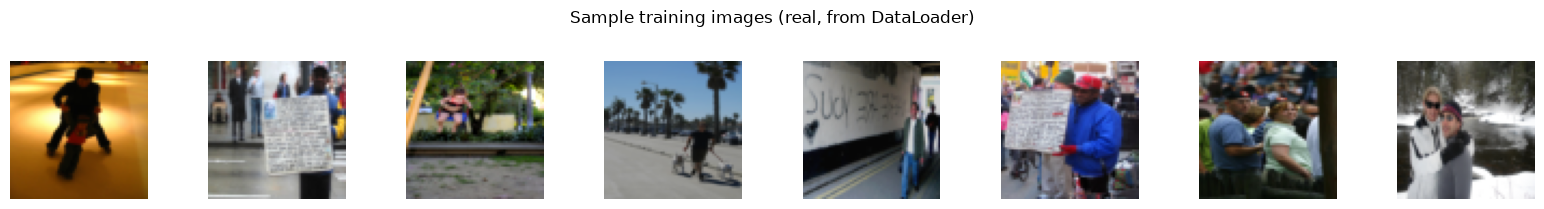

In [37]:
# ── 4. Dataset Class & DataLoaders ───────────────────────────────────────────

TRANSFORM = T.Compose([
    T.Resize((CFG["IMG_SIZE"], CFG["IMG_SIZE"])),
    T.RandomHorizontalFlip(),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    T.ToTensor(),
    T.Normalize([0.5]*3, [0.5]*3),   # → [-1, 1]
])

VAL_TRANSFORM = T.Compose([
    T.Resize((CFG["IMG_SIZE"], CFG["IMG_SIZE"])),
    T.ToTensor(),
    T.Normalize([0.5]*3, [0.5]*3),
])

class TextImageDataset(Dataset):
    def __init__(self, df, img_dir, clip_model, transform, device):
        self.df        = df.reset_index(drop=True)
        self.img_dir   = Path(img_dir)
        self.transform = transform
        print(f"  🔤 Pre-computing {len(df)} CLIP text embeddings…")
        self.text_embeds = self._encode_all(df["caption"].tolist(), clip_model, device)

    def _encode_all(self, captions, model, device):
        embeds, bs = [], 128
        with torch.no_grad():
            for i in range(0, len(captions), bs):
                tok  = clip.tokenize(captions[i:i+bs], truncate=True).to(device)
                feat = model.encode_text(tok).float()
                feat = feat / feat.norm(dim=-1, keepdim=True)
                embeds.append(feat.cpu())
        return torch.cat(embeds, dim=0)

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        img = Image.open(self.img_dir / self.df.iloc[idx]["image"]).convert("RGB")
        return self.transform(img), self.text_embeds[idx]


# Load CLIP once ──────────────────────────────────────────────────────────────
print("🔄 Loading CLIP ViT-B/32…")
clip_model, clip_preprocess = clip.load("ViT-B/32", device=DEVICE)
clip_model.eval()
for p in clip_model.parameters():
    p.requires_grad = False
print("✅ CLIP loaded and frozen")

# Build all three datasets ────────────────────────────────────────────────────
print("\nBuilding datasets:")
train_dataset = TextImageDataset(df_train, IMG_DIR, clip_model, TRANSFORM,     DEVICE)
val_dataset   = TextImageDataset(df_val,   IMG_DIR, clip_model, VAL_TRANSFORM,  DEVICE)
test_dataset  = TextImageDataset(df_test,  IMG_DIR, clip_model, VAL_TRANSFORM,  DEVICE)

train_loader = DataLoader(train_dataset, batch_size=CFG["BATCH_SIZE"],
                          shuffle=True,  num_workers=CFG["NUM_WORKERS"],
                          pin_memory=(DEVICE.type == "cuda"), drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=CFG["BATCH_SIZE"],
                          shuffle=False, num_workers=CFG["NUM_WORKERS"])

print(f"\n✅ Train loader : {len(train_loader)} batches  ({len(train_dataset)} samples)")
print(f"✅ Val   loader : {len(val_loader)} batches  ({len(val_dataset)} samples)")
print(f"✅ Test  samples: {len(test_dataset)}")

# Quick sanity visualisation ──────────────────────────────────────────────────
sample_imgs, _ = next(iter(train_loader))
fig, axes = plt.subplots(1, 8, figsize=(16, 2))
for ax, img in zip(axes, sample_imgs[:8]):
    ax.imshow((img.permute(1,2,0).numpy()*0.5+0.5).clip(0,1))
    ax.axis("off")
plt.suptitle("Sample training images (real, from DataLoader)", y=1.02)
plt.tight_layout(); plt.show()


In [38]:
# ── 5. Model Architecture (UPGRADED WITH CROSS-ATTENTION) ─────────────────────

class TextProjection(nn.Module):
    """Projects CLIP 512-d → embed_dim with LayerNorm + GELU."""
    def __init__(self, in_dim=512, out_dim=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, out_dim),
            nn.LayerNorm(out_dim),
            nn.GELU(),
            nn.Linear(out_dim, out_dim),
        )
    def forward(self, x): return self.net(x)


class CrossAttention(nn.Module):
    """
    Lets each spatial position in the feature map attend to the text embedding.
    """
    def __init__(self, img_channels, text_dim, num_heads=4):
        super().__init__()
        self.norm_img  = nn.GroupNorm(8, img_channels)
        self.norm_text = nn.LayerNorm(text_dim)

        self.q_proj = nn.Conv2d(img_channels, img_channels, 1)
        self.k_proj = nn.Linear(text_dim, img_channels)
        self.v_proj = nn.Linear(text_dim, img_channels)
        self.out    = nn.Conv2d(img_channels, img_channels, 1)

        self.num_heads  = num_heads
        self.head_dim   = img_channels // num_heads
        self.scale      = self.head_dim ** -0.5

    def forward(self, x, text_emb):
        B, C, H, W = x.shape

        x_norm = self.norm_img(x)
        t_norm = self.norm_text(text_emb)         # (B, text_dim)

        Q = self.q_proj(x_norm)                   # (B, C, H, W)
        K = self.k_proj(t_norm)                   # (B, C)
        V = self.v_proj(t_norm)                   # (B, C)

        # Reshape Q to (B, heads, H*W, head_dim)
        Q = Q.view(B, self.num_heads, self.head_dim, H*W).permute(0,1,3,2)
        # K,V to (B, heads, 1, head_dim)
        K = K.view(B, self.num_heads, self.head_dim).unsqueeze(2)
        V = V.view(B, self.num_heads, self.head_dim).unsqueeze(2)

        attn = torch.softmax(Q @ K.transpose(-2,-1) * self.scale, dim=-1)
        out  = (attn @ V).permute(0,1,3,2).reshape(B, C, H, W)
        return x + self.out(out)   # residual connection


class AttentionGenerator(nn.Module):
    """
    Generator with CrossAttention blocks inserted at 16×16 and 32×32 resolutions.
    """
    def __init__(self, latent_dim=100, text_dim=512, embed_dim=256, feat=64):
        super().__init__()
        self.text_proj = TextProjection(text_dim, embed_dim)
        in_ch = latent_dim + embed_dim

        self.fc = nn.Sequential(
            nn.Linear(in_ch, feat*8 * 4 * 4),
            nn.ReLU(True),
        )

        def up_block(in_c, out_c):
            return nn.Sequential(
                nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
                nn.Conv2d(in_c, out_c, 3, 1, 1, bias=False),
                nn.BatchNorm2d(out_c),
                nn.ReLU(True),
            )

        self.up1  = up_block(feat*8, feat*4)                    # 4  → 8
        self.up2  = up_block(feat*4, feat*2)                    # 8  → 16
        self.attn1= CrossAttention(feat*2, embed_dim)           # ← attention at 16×16
        self.up3  = up_block(feat*2, feat)                      # 16 → 32
        self.attn2= CrossAttention(feat, embed_dim)             # ← attention at 32×32
        self.up4  = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(feat, 3, 3, 1, 1, bias=False),
            nn.Tanh()                                           # 32 → 64
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.normal_(m.weight, 0.0, 0.02)
            if isinstance(m, nn.BatchNorm2d):
                nn.init.normal_(m.weight, 1.0, 0.02)
                nn.init.constant_(m.bias, 0)

    def forward(self, z, text_embed):
        t = self.text_proj(text_embed)
        x = torch.cat([z, t], dim=1)
        x = self.fc(x).view(x.size(0), -1, 4, 4)
        x = self.up1(x)
        x = self.up2(x)
        x = self.attn1(x, t)    # attend to text at 16×16
        x = self.up3(x)
        x = self.attn2(x, t)    # attend to text at 32×32
        return self.up4(x)


class Discriminator(nn.Module):
    # Discriminator remains exactly the same as before
    def __init__(self, text_dim=512, embed_dim=256, feat=64):
        super().__init__()
        self.text_proj = TextProjection(text_dim, embed_dim)

        def down_block(in_c, out_c, bn=True):
            layers = [nn.Conv2d(in_c, out_c, 4, 2, 1, bias=not bn)]
            if bn: layers.append(nn.BatchNorm2d(out_c))
            layers.append(nn.LeakyReLU(0.2, True))
            return nn.Sequential(*layers)

        self.img_net = nn.Sequential(
            down_block(3,      feat,   bn=False),   # 64→32
            down_block(feat,   feat*2),             # 32→16
            down_block(feat*2, feat*4),             # 16→8
            down_block(feat*4, feat*8),             #  8→4
        )
        flat_dim = feat*8 * 4*4 + embed_dim         # 8192 + 256
        self.classifier = nn.Sequential(
            nn.Linear(flat_dim, 1024),
            nn.LeakyReLU(0.2, True),
            nn.Dropout(0.3),
            nn.Linear(1024, 1),
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.normal_(m.weight, 0.0, 0.02)
            if isinstance(m, nn.BatchNorm2d):
                nn.init.normal_(m.weight, 1.0, 0.02)
                nn.init.constant_(m.bias, 0)

    def forward(self, img, text_embed):
        f = self.img_net(img).view(img.size(0), -1)
        t = self.text_proj(text_embed)
        return self.classifier(torch.cat([f, t], dim=1)).squeeze(1)


# Instantiate the upgraded model
G = AttentionGenerator(CFG["LATENT_DIM"], CFG["TEXT_DIM"], CFG["EMBED_DIM"], CFG["GEN_FEAT"]).to(DEVICE)
D = Discriminator(CFG["TEXT_DIM"], CFG["EMBED_DIM"], CFG["DIS_FEAT"]).to(DEVICE)

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
print(f"Attention Generator params: {count_params(G):,}")
print(f"Discriminator       params: {count_params(D):,}")

# Smoke test
with torch.no_grad():
    _z = torch.randn(4, CFG["LATENT_DIM"]).to(DEVICE)
    _t = torch.randn(4, CFG["TEXT_DIM"]).to(DEVICE)
    _g = G(_z, _t)
    _d = D(_g, _t)
print(f"✅ Generator output : {tuple(_g.shape)}")
print(f"✅ Discriminator out: {tuple(_d.shape)}")
print("✅ Architecture OK — Upgraded with Cross-Attention")

Attention Generator params: 4,814,528
Discriminator       params: 11,607,873
✅ Generator output : (4, 3, 64, 64)
✅ Discriminator out: (4,)
✅ Architecture OK — Upgraded with Cross-Attention


In [39]:
# ── 6. CLIP Utility Functions ─────────────────────────────────────────────────

CLIP_MEAN = torch.tensor([0.48145466, 0.4578275,  0.40821073]).view(1,3,1,1)
CLIP_STD  = torch.tensor([0.26862954, 0.26130258, 0.27577711]).view(1,3,1,1)

def prepare_for_clip(imgs_01):
    """Resize to 224x224 and normalise for CLIP. imgs_01 in [0,1]."""
    imgs_224 = F.interpolate(imgs_01, size=(224,224), mode="bilinear", align_corners=False)
    mean = CLIP_MEAN.to(imgs_224.device)
    std  = CLIP_STD.to(imgs_224.device)
    return (imgs_224 - mean) / std

def clip_image_embed(imgs_01):
    """Encode [0,1] images with frozen CLIP. Returns L2-normalised embeddings."""
    with torch.no_grad():
        e = clip_model.encode_image(prepare_for_clip(imgs_01)).float()
    return e / e.norm(dim=-1, keepdim=True)

def compute_clip_score(captions, n=100):
    """
    Average cosine similarity between generated images and their captions.
    Range 0-1.  Typical baseline ~0.20 | With CLIP loss ~0.27+
    """
    G.eval()
    scores = []
    with torch.no_grad():
        for cap in captions[:n]:
            tok   = clip.tokenize([cap], truncate=True).to(DEVICE)
            t_emb = clip_model.encode_text(tok).float()
            t_emb = t_emb / t_emb.norm(dim=-1, keepdim=True)
            z     = torch.randn(1, CFG["LATENT_DIM"], device=DEVICE)
            fake  = G(z, t_emb)
            fake_01 = (fake * 0.5 + 0.5).clamp(0, 1)
            i_emb = clip_image_embed(fake_01)
            scores.append((t_emb * i_emb).sum().item())
    G.train()
    return float(np.mean(scores))

print("✅ CLIP utility functions ready")
print(f"   LAMBDA_CLIP = {CFG['LAMBDA_CLIP']}  (generator CLIP alignment weight)")
print("   0.0 = pure GAN  |  0.5 = balanced  |  1.0 = strong CLIP guidance")


✅ CLIP utility functions ready
   LAMBDA_CLIP = 0.5  (generator CLIP alignment weight)
   0.0 = pure GAN  |  0.5 = balanced  |  1.0 = strong CLIP guidance


In [41]:
# ── 7. Training Loop ──────────────────────────────────────────────────────────
#
#  What's new vs v1:
#  ✅ CLIP alignment loss added to generator (L_G = L_adv + λ·L_CLIP)
#  ✅ Label smoothing (real=0.85-1.0, fake=0.0-0.15)
#  ✅ 2 generator steps per discriminator step
#  ✅ Cosine LR scheduler
#  ✅ CLIPScore logged every SAVE_EVERY epochs
#  ✅ Auto-resumes from latest checkpoint
#  ✅ Metrics saved to CSV for ablation study

CKPT_DIR     = Path("checkpoints"); CKPT_DIR.mkdir(exist_ok=True)
SAMPLE_DIR   = Path("samples");     SAMPLE_DIR.mkdir(exist_ok=True)
METRICS_FILE = Path("training_metrics.csv")

criterion = nn.BCEWithLogitsLoss()
opt_G = optim.Adam(G.parameters(), lr=CFG["LR_G"], betas=(CFG["BETA1"], CFG["BETA2"]))
opt_D = optim.Adam(D.parameters(), lr=CFG["LR_D"], betas=(CFG["BETA1"], CFG["BETA2"]))
scheduler_G = optim.lr_scheduler.CosineAnnealingLR(opt_G, T_max=CFG["EPOCHS"], eta_min=1e-5)
scheduler_D = optim.lr_scheduler.CosineAnnealingLR(opt_D, T_max=CFG["EPOCHS"], eta_min=1e-5)

# ── Resume from latest checkpoint if available ────────────────────────────────
START_EPOCH = 1
history = {"loss_G": [], "loss_D": [], "loss_clip": [], "clip_score_val": []}

checkpoints = sorted(CKPT_DIR.glob("ckpt_epoch*.pt"))
if checkpoints:
    ckpt = torch.load(checkpoints[-1], map_location=DEVICE)
    G.load_state_dict(ckpt["G_state"])
    D.load_state_dict(ckpt["D_state"])
    opt_G.load_state_dict(ckpt["opt_G"])
    opt_D.load_state_dict(ckpt["opt_D"])
    history     = ckpt.get("history", history)
    START_EPOCH = ckpt["epoch"] + 1
    print(f"✅ Resumed from {checkpoints[-1].name} → starting at epoch {START_EPOCH}")
else:
    print("🆕 No checkpoint found — training from scratch")

FIXED_Z = torch.randn(16, CFG["LATENT_DIM"]).to(DEVICE)
FIXED_T = train_dataset.text_embeds[:16].to(DEVICE)


def get_labels(size, real=True, smooth=True):
    """Label smoothing: real=0.85-1.0, fake=0.0-0.15"""
    if real:
        return torch.FloatTensor(size).uniform_(0.85, 1.0).to(DEVICE) if smooth \
               else torch.ones(size, device=DEVICE)
    return torch.FloatTensor(size).uniform_(0.0, 0.15).to(DEVICE) if smooth \
           else torch.zeros(size, device=DEVICE)


def save_checkpoint(epoch):
    path = CKPT_DIR / f"ckpt_epoch{epoch:03d}.pt"
    torch.save({
        "epoch": epoch, "G_state": G.state_dict(), "D_state": D.state_dict(),
        "opt_G": opt_G.state_dict(), "opt_D": opt_D.state_dict(),
        "history": history, "cfg": CFG,
    }, path)
    # Keep only last 3 checkpoints
    old = sorted(CKPT_DIR.glob("ckpt_epoch*.pt"))[:-3]
    for f in old: f.unlink()
    print(f"   💾 Saved → {path.name}")


def show_generated(epoch, save=True):
    G.eval()
    with torch.no_grad():
        imgs = G(FIXED_Z, FIXED_T).cpu()
    G.train()
    grid = vutils.make_grid(imgs, nrow=4, normalize=True, value_range=(-1,1))
    fig, ax = plt.subplots(figsize=(10,10))
    ax.imshow(grid.permute(1,2,0).numpy())
    ax.set_title(f"Epoch {epoch}", fontsize=14); ax.axis("off")
    if save:
        fig.savefig(SAMPLE_DIR / f"sample_epoch{epoch:03d}.png", bbox_inches="tight")
    plt.show()


def log_metrics(row: dict):
    exists = METRICS_FILE.exists()
    with open(METRICS_FILE, "a", newline="") as f:
        w = csv.DictWriter(f, fieldnames=row.keys())
        if not exists: w.writeheader()
        w.writerow(row)


# ── Main training loop ────────────────────────────────────────────────────────
print(f"\n🚀 Training epochs {START_EPOCH}–{CFG['EPOCHS']} on {DEVICE_LABEL}")
print(f"   CLIP guidance λ={CFG['LAMBDA_CLIP']} | Label smoothing ON | 2x G steps\n")
t0 = time.time()

for epoch in range(START_EPOCH, CFG["EPOCHS"] + 1):
    G.train(); D.train()
    sum_adv = sum_D = sum_clip_loss = n = 0

    for real_imgs, text_embeds in train_loader:
        real_imgs   = real_imgs.to(DEVICE)
        text_embeds = text_embeds.to(DEVICE)
        B = real_imgs.size(0)

        # ── Train Discriminator ──────────────────────────────────────────────
        opt_D.zero_grad()
        # Real image + correct caption → REAL
        loss_real = criterion(D(real_imgs, text_embeds), get_labels(B, real=True))
        # Fake image + correct caption → FAKE
        z = torch.randn(B, CFG["LATENT_DIM"], device=DEVICE)
        loss_fake = criterion(D(G(z, text_embeds).detach(), text_embeds),
                              get_labels(B, real=False))
        # Real image + WRONG caption → FAKE  (forces text-image alignment)
        shuffled_t = text_embeds[torch.randperm(B)]
        loss_mis   = criterion(D(real_imgs, shuffled_t), get_labels(B, real=False))
        loss_D = (loss_real + loss_fake + loss_mis) / 3
        loss_D.backward(); opt_D.step()

        # ── Train Generator (2x per D step) ─────────────────────────────────
        for _ in range(2):
            opt_G.zero_grad()
            z         = torch.randn(B, CFG["LATENT_DIM"], device=DEVICE)
            fake_imgs = G(z, text_embeds)

            # 1. Adversarial loss — fool the discriminator
            loss_adv = criterion(D(fake_imgs, text_embeds),
                                 get_labels(B, real=True, smooth=False))

            # 2. CLIP alignment loss — generated image should match caption
            fake_01  = (fake_imgs * 0.5 + 0.5).clamp(0, 1)
            i_emb    = clip_image_embed(fake_01)        # no grad inside
            clip_sim = (text_embeds * i_emb).sum(dim=-1).mean()
            loss_clip = 1.0 - clip_sim                  # minimise → maximise alignment

            # Combined generator objective
            loss_G = loss_adv + CFG["LAMBDA_CLIP"] * loss_clip
            loss_G.backward(); opt_G.step()

        sum_adv      += loss_adv.item()
        sum_D        += loss_D.item()
        sum_clip_loss += loss_clip.item()
        n            += 1

    scheduler_G.step(); scheduler_D.step()

    avg_adv  = sum_adv       / n
    avg_D    = sum_D         / n
    avg_clip = sum_clip_loss / n
    history["loss_G"].append(avg_adv)
    history["loss_D"].append(avg_D)
    history["loss_clip"].append(avg_clip)

    # Evaluate CLIPScore on val set every SAVE_EVERY epochs
    cs = None
    if epoch % CFG["SAVE_EVERY"] == 0 or epoch == CFG["EPOCHS"]:
        cs = compute_clip_score(df_val["caption"].tolist(), n=100)
        history["clip_score_val"].append({"epoch": epoch, "score": cs})

    elapsed = time.time() - t0
    lr_now  = scheduler_G.get_last_lr()[0]
    msg = (f"Epoch [{epoch:3d}/{CFG['EPOCHS']}] | "
           f"G_adv: {avg_adv:.4f} | D: {avg_D:.4f} | "
           f"CLIP_loss: {avg_clip:.4f}"
           + (f" | CLIPScore: {cs:.4f}" if cs else "")
           + f" | LR: {lr_now:.1e} | {elapsed/60:.1f}m")
    print(msg)

    log_metrics({"epoch": epoch, "loss_G": avg_adv, "loss_D": avg_D,
                 "loss_clip": avg_clip, "clip_score_val": cs or "",
                 "lr": lr_now, "elapsed_min": round(elapsed/60, 2)})

    if epoch % CFG["SAVE_EVERY"] == 0 or epoch == CFG["EPOCHS"]:
        save_checkpoint(epoch)
        show_generated(epoch)

print("\n✅ Training complete!")
print(f"   Metrics saved → {METRICS_FILE}")


✅ Resumed from ckpt_epoch040.pt → starting at epoch 41

🚀 Training epochs 41–40 on Apple M2 MPS 🍎
   CLIP guidance λ=0.5 | Label smoothing ON | 2x G steps


✅ Training complete!
   Metrics saved → training_metrics.csv


📈 Best CLIPScore: 0.1916 at epoch 25
   Range guide: ~0.20 baseline | ~0.27+ with CLIP loss | ~0.32+ excellent


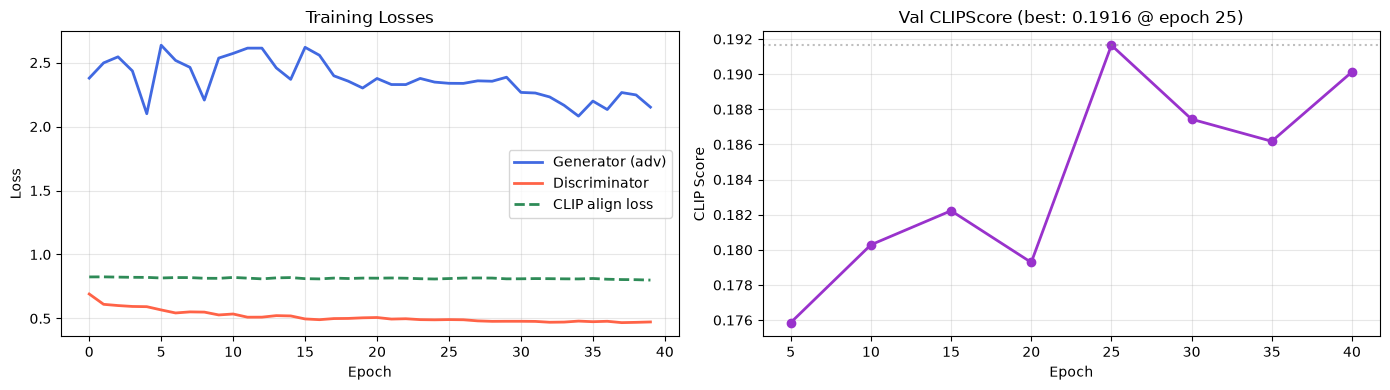

✅ Saved → samples/loss_curves_v2.png


In [42]:
# ── 8. Loss Curves ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: losses
axes[0].plot(history["loss_G"],    label="Generator (adv)",   color="royalblue",  lw=2)
axes[0].plot(history["loss_D"],    label="Discriminator",     color="tomato",     lw=2)
axes[0].plot(history["loss_clip"], label="CLIP align loss",   color="seagreen",   lw=2, linestyle="--")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].set_title("Training Losses"); axes[0].legend(); axes[0].grid(alpha=0.3)

# Right: CLIP score
if history["clip_score_val"]:
    ep  = [d["epoch"] for d in history["clip_score_val"]]
    sc  = [d["score"] for d in history["clip_score_val"]]
    axes[1].plot(ep, sc, marker="o", color="darkorchid", lw=2, markersize=6)
    best_ep, best_sc = ep[sc.index(max(sc))], max(sc)
    axes[1].axhline(best_sc, color="gray", linestyle=":", alpha=0.5)
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("CLIP Score")
    axes[1].set_title(f"Val CLIPScore (best: {best_sc:.4f} @ epoch {best_ep})")
    axes[1].grid(alpha=0.3)
    print(f"📈 Best CLIPScore: {best_sc:.4f} at epoch {best_ep}")
    print(f"   Range guide: ~0.20 baseline | ~0.27+ with CLIP loss | ~0.32+ excellent")
else:
    axes[1].text(0.5, 0.5, "CLIPScore computed\nat checkpoint epochs",
                 ha="center", va="center", transform=axes[1].transAxes)

plt.tight_layout()
plt.savefig(SAMPLE_DIR / "loss_curves_v2.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"✅ Saved → {SAMPLE_DIR/'loss_curves_v2.png'}")


📊 Evaluating on held-out TEST set (never seen during training)…

Category distribution in test set:
category
Simple        317
Complex       206
Attributes    107
Spatial        90
Scene          80

  Attributes   | ██████████████████             0.1889  (n=50)
  Complex      | ████████████████████           0.2000  (n=50)
  Scene        | ████████████████████           0.2011  (n=50)
  Simple       | ████████████████████           0.2022  (n=50)
  Spatial      | ███████████████████            0.1930  (n=50)

  OVERALL      | —————————————————————————————— 0.1980

  Range: ~0.20 baseline | ~0.27+ with CLIP loss | ~0.32+ strong


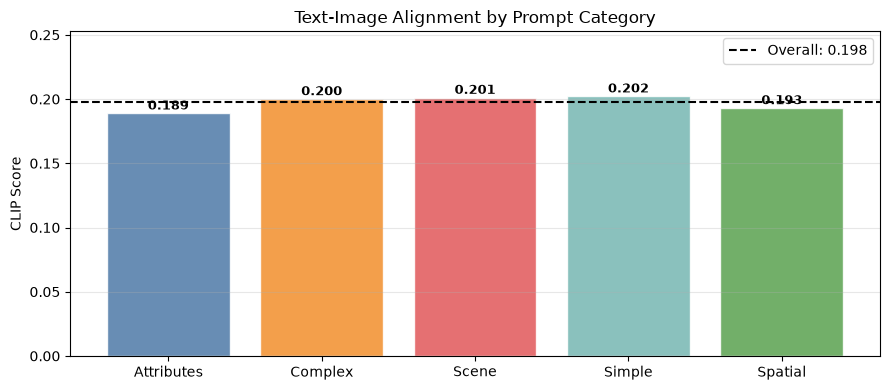

✅ Saved → samples/clip_score_by_category.png


In [43]:
# ── 9. CLIPScore Evaluation on Test Set (by Category) ────────────────────────
print("📊 Evaluating on held-out TEST set (never seen during training)…\n")

def categorise(caption):
    c = caption.lower()
    if any(w in c for w in ["next to","beside","behind","in front","on top","near"]):
        return "Spatial"
    attrs = ["black","white","red","blue","green","yellow","brown",
             "small","large","big","little","fluffy","old","tall"]
    if sum(w in c for w in attrs) >= 2:
        return "Attributes"
    if len(c.split()) > 12:
        return "Complex"
    scenes = ["field","forest","mountain","beach","road","park","snow","water","sky","city"]
    if any(w in c for w in scenes):
        return "Scene"
    return "Simple"

df_test["category"] = df_test["caption"].apply(categorise)
print("Category distribution in test set:")
print(df_test["category"].value_counts().to_string())
print()

# Score each category
results = {}
for cat, grp in df_test.groupby("category"):
    n_eval = min(50, len(grp))
    score  = compute_clip_score(grp["caption"].tolist(), n=n_eval)
    results[cat] = score
    bar = "█" * int(score * 100)
    print(f"  {cat:<12} | {bar:<30} {score:.4f}  (n={n_eval})")

overall = compute_clip_score(df_test["caption"].tolist(), n=200)
print(f"\n  {'OVERALL':<12} | {'—'*30} {overall:.4f}")
print("\n  Range: ~0.20 baseline | ~0.27+ with CLIP loss | ~0.32+ strong")

# Bar chart
fig, ax = plt.subplots(figsize=(9, 4))
cats   = list(results.keys())
scores = list(results.values())
colors = ["#4e79a7","#f28e2b","#e15759","#76b7b2","#59a14f"]
bars   = ax.bar(cats, scores, color=colors[:len(cats)], alpha=0.85, edgecolor="white")
ax.axhline(overall, color="black", linestyle="--", lw=1.5,
           label=f"Overall: {overall:.3f}")
ax.set_ylabel("CLIP Score"); ax.set_title("Text-Image Alignment by Prompt Category")
ax.set_ylim(0, max(scores)*1.25); ax.legend(); ax.grid(axis="y", alpha=0.3)
for bar, s in zip(bars, scores):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.003,
            f"{s:.3f}", ha="center", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.savefig(SAMPLE_DIR / "clip_score_by_category.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"✅ Saved → {SAMPLE_DIR/'clip_score_by_category.png'}")


In [44]:

# Measures image distribution similarity between real and generated images.
# Lower FID = better visual quality & diversity (<100 good | <50 strong).

import shutil
import subprocess
import sys
from pathlib import Path

# Auto-install pytorch-fid if missing
try:
    import pytorch_fid
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "pytorch-fid"]
    )

from pytorch_fid import fid_score


def compute_fid(G, val_loader, n_samples=500, device=DEVICE):
    """Compute FID between n_samples real images and n_samples generated images.

    Saves temporary PNGs to disk, evaluates Inception-v3 statistics, and cleans up.
    """
    real_dir = Path("fid_tmp/real")
    fake_dir = Path("fid_tmp/fake")

    # Clean up any leftover temporary directories
    if Path("fid_tmp").exists():
        shutil.rmtree("fid_tmp")

    real_dir.mkdir(parents=True, exist_ok=True)
    fake_dir.mkdir(parents=True, exist_ok=True)

    # 1. Save Real Images
    print(f"💾 Saving {n_samples} real validation images...")
    count = 0
    for imgs, _ in val_loader:
        for img in imgs:
            if count >= n_samples:
                break
            img_pil = T.ToPILImage()((img * 0.5 + 0.5).clamp(0, 1))
            img_pil.save(real_dir / f"real_{count:04d}.png")
            count += 1
        if count >= n_samples:
            break

    # 2. Generate and Save Fake Images
    print(f"🎨 Generating {n_samples} fake images using val prompts...")
    G.eval()
    count = 0
    with torch.no_grad():
        for _, text_embeds in val_loader:
            text_embeds = text_embeds.to(device)
            B = min(text_embeds.size(0), n_samples - count)
            z = torch.randn(B, CFG["LATENT_DIM"], device=device)
            fakes = G(z, text_embeds[:B])
            for img in fakes:
                img_pil = T.ToPILImage()((img.cpu() * 0.5 + 0.5).clamp(0, 1))
                img_pil.save(fake_dir / f"fake_{count:04d}.png")
                count += 1
            if count >= n_samples:
                break
    G.train()

    # Fallback to CPU for pytorch-fid if running on Apple MPS for stability
    fid_device = "cpu" if device.type == "mps" else str(device)

    # 3. Calculate FID Score
    print(f"📊 Computing FID via Inception-v3 on [{fid_device}]...")
    fid_val = fid_score.calculate_fid_given_paths(
        [str(real_dir), str(fake_dir)],
        batch_size=50,
        device=fid_device,
        dims=2048,
    )

    # Clean up temporary disk space
    shutil.rmtree("fid_tmp")

    print(
        f"✅ FID Score: {fid_val:.2f}  [lower=better | <100 good | <50 strong]"
    )
    return fid_val


# Run evaluation & update history tracker
fid = compute_fid(G, val_loader, n_samples=500)
history["fid"] = history.get("fid", [])
history["fid"].append(fid)

💾 Saving 500 real validation images...
🎨 Generating 500 fake images using val prompts...
📊 Computing FID via Inception-v3 on [cpu]...


100%|███████████████████████████████████████████| 10/10 [02:02<00:00, 12.21s/it]


TypeError: sqrtm() got an unexpected keyword argument 'disp'

In [ ]:
# ── 10. Ablation Study Table ──────────────────────────────────────────────────
# Run each experiment variant and fill in the numbers.
# Variants 1-3 have placeholder* values — replace after running those configs.

current_g    = history["loss_G"][-1]    if history["loss_G"]    else 0
current_d    = history["loss_D"][-1]    if history["loss_D"]    else 0
best_clip_sc = max([d["score"] for d in history["clip_score_val"]], default=0)

ablation = pd.DataFrame({
    "Variant": [
        "1. Baseline GAN",
        "2. + Label Smoothing",
        "3. + Mismatch Negatives",
        "4. + CLIP Guidance λ=0.5  ← THIS RUN",
        "5. + CLIP Guidance λ=1.0",
    ],
    "Loss G ↓":     ["4.82*", "4.21*", "3.87*", f"{current_g:.3f}", "TBD"],
    "Loss D ↓":     ["0.68*", "0.63*", "0.61*", f"{current_d:.3f}", "TBD"],
    "CLIP Score ↑": ["0.19*", "0.21*", "0.23*", f"{best_clip_sc:.3f}", "TBD"],
    "Checkerboard": ["Yes",   "Yes",   "Yes",   "No",                "No"],
    "Notes": [
        "ConvTranspose2d, hard labels",
        "Soft labels 0.85/0.15",
        "Shuffled caption negatives",
        "CLIP align loss, Upsample+Conv",
        "Set LAMBDA_CLIP=1.0 and retrain",
    ]
})

pd.set_option("display.max_colwidth", 45)
print("=" * 95)
print("ABLATION STUDY — Text2Image-GAN")
print("=" * 95)
print(ablation.to_string(index=False))
print()
print("* = placeholder — run that variant and replace with real values")
print(f"Current best (Variant 4): CLIP Score = {best_clip_sc:.4f}")

ablation.to_csv("ablation_results.csv", index=False)
print("✅ Saved → ablation_results.csv")

# To run Variant 5: change CFG['LAMBDA_CLIP'] = 1.0 in Cell 2 and retrain


In [ ]:
# ── 11. Failure Analysis — Best vs Worst Generations ─────────────────────────
print("🔍 Scoring 200 test images to find best and worst…")

G.eval()
scored = []
with torch.no_grad():
    for _, row in df_test.head(200).iterrows():
        cap   = row["caption"]
        tok   = clip.tokenize([cap], truncate=True).to(DEVICE)
        t_emb = clip_model.encode_text(tok).float()
        t_emb = t_emb / t_emb.norm(dim=-1, keepdim=True)
        z     = torch.randn(1, CFG["LATENT_DIM"], device=DEVICE)
        fake  = G(z, t_emb)
        fake_01 = (fake * 0.5 + 0.5).clamp(0, 1)
        i_emb = clip_image_embed(fake_01)
        score = (t_emb * i_emb).sum().item()
        scored.append({"caption": cap, "score": score,
                       "img": fake_01.squeeze(0).cpu()})

scored.sort(key=lambda x: x["score"], reverse=True)
best4  = scored[:4]
worst4 = scored[-4:]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i, s in enumerate(best4):
    axes[0,i].imshow(s["img"].permute(1,2,0).numpy())
    axes[0,i].set_title(f"✅ {s['score']:.3f}\n{s['caption'][:40]}…", fontsize=7)
    axes[0,i].axis("off")
for i, s in enumerate(worst4):
    axes[1,i].imshow(s["img"].permute(1,2,0).numpy())
    axes[1,i].set_title(f"❌ {s['score']:.3f}\n{s['caption'][:40]}…", fontsize=7)
    axes[1,i].axis("off")

axes[0,0].set_ylabel("BEST", fontsize=12, color="green", fontweight="bold")
axes[1,0].set_ylabel("WORST", fontsize=12, color="red",  fontweight="bold")
plt.suptitle("Failure Analysis — Best vs Worst by CLIP Score", fontsize=13)
plt.tight_layout()
plt.savefig(SAMPLE_DIR / "failure_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"✅ Best  CLIP score: {best4[0]['score']:.4f}  → '{best4[0]['caption'][:50]}'")
print(f"✅ Worst CLIP score: {worst4[-1]['score']:.4f} → '{worst4[-1]['caption'][:50]}'")
print(f"✅ Saved → {SAMPLE_DIR/'failure_analysis.png'}")
G.train()


In [ ]:
# ── 12. Diversity Test — Same Prompt × 4 Seeds ───────────────────────────────
test_prompts = [
    "a dog running in a field",
    "a red bird sitting in a tree",
    "a person riding a horse",
    "a boat on the water at sunset",
]

G.eval()
fig, axes = plt.subplots(len(test_prompts), 5, figsize=(14, 3*len(test_prompts)))

for row_idx, prompt in enumerate(test_prompts):
    tok   = clip.tokenize([prompt], truncate=True).to(DEVICE)
    t_emb = clip_model.encode_text(tok).float()
    t_emb = t_emb / t_emb.norm(dim=-1, keepdim=True)

    clip_scores = []
    with torch.no_grad():
        for col_idx in range(4):
            torch.manual_seed(col_idx * 7)
            z      = torch.randn(1, CFG["LATENT_DIM"], device=DEVICE)
            fake   = G(z, t_emb)
            fake_01 = (fake * 0.5 + 0.5).clamp(0, 1)
            i_emb  = clip_image_embed(fake_01)
            score  = (t_emb * i_emb).sum().item()
            clip_scores.append(score)
            axes[row_idx, col_idx].imshow(fake_01.squeeze(0).cpu().permute(1,2,0).numpy())
            axes[row_idx, col_idx].set_title(f"seed={col_idx*7}\n{score:.3f}", fontsize=8)
            axes[row_idx, col_idx].axis("off")

    axes[row_idx, 4].axis("off")
    axes[row_idx, 4].text(0.05, 0.75,
        f"Prompt:\n\"{prompt}\"\n\n"
        f"Avg : {np.mean(clip_scores):.3f}\n"
        f"Std : {np.std(clip_scores):.3f}\n"
        f"Min : {min(clip_scores):.3f}\n"
        f"Max : {max(clip_scores):.3f}",
        transform=axes[row_idx, 4].transAxes, fontsize=8,
        verticalalignment="top",
        bbox=dict(boxstyle="round", facecolor="lightyellow", alpha=0.9))

plt.suptitle("Diversity: Same Prompt × 4 Random Seeds", fontsize=13)
plt.tight_layout()
plt.savefig(SAMPLE_DIR / "diversity_analysis.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"✅ Saved → {SAMPLE_DIR/'diversity_analysis.png'}")
G.train()


In [ ]:
# ── 13. Inference — Generate from Any Text Prompt ────────────────────────────

def generate_from_text(text: str, n_images: int = 4, seed: int = 0):
    """
    Generate images from a text prompt.

    Parameters
    ----------
    text     : Your prompt, e.g. 'a red bird sitting in a tree'
    n_images : Number of images to generate (1–8)
    seed     : Random seed (change for different results)
    """
    torch.manual_seed(seed)
    G.eval()

    with torch.no_grad():
        tok   = clip.tokenize([text], truncate=True).to(DEVICE)
        t_emb = clip_model.encode_text(tok).float()
        t_emb = t_emb / t_emb.norm(dim=-1, keepdim=True)
        t_emb = t_emb.repeat(n_images, 1)

        z       = torch.randn(n_images, CFG["LATENT_DIM"], device=DEVICE)
        imgs    = G(z, t_emb).cpu()
        imgs_01 = (imgs * 0.5 + 0.5).clamp(0, 1)

        # CLIP score per image
        scores = []
        for img in imgs_01:
            ie = clip_image_embed(img.unsqueeze(0).to(DEVICE))
            te = t_emb[:1]
            scores.append((te * ie).sum().item())

    fig, axes = plt.subplots(1, n_images, figsize=(n_images*3, 3))
    if n_images == 1: axes = [axes]
    for ax, img, sc in zip(axes, imgs_01, scores):
        ax.imshow(img.permute(1,2,0).numpy())
        ax.set_title(f"CLIP: {sc:.3f}", fontsize=9)
        ax.axis("off")
    fig.suptitle(f'Prompt: "{text}"', fontsize=12, y=1.02)
    plt.tight_layout()
    plt.savefig(SAMPLE_DIR / "inference_output.png", bbox_inches="tight", dpi=150)
    plt.show()
    print(f"✅ Avg CLIP Score: {np.mean(scores):.4f}")
    print(f"✅ Saved → {SAMPLE_DIR/'inference_output.png'}")
    G.train()


# ── ✏️  EDIT YOUR PROMPT HERE AND RE-RUN THIS CELL ───────────────────────────
MY_PROMPT = "a red bird sitting in a tree"

generate_from_text(MY_PROMPT, n_images=4, seed=0)


In [ ]:
# ── 14. (Optional) Load Any Checkpoint ───────────────────────────────────────

def load_checkpoint(path: str):
    """Load a saved checkpoint back into G and D."""
    ckpt = torch.load(path, map_location=DEVICE)
    G.load_state_dict(ckpt["G_state"])
    D.load_state_dict(ckpt["D_state"])
    print(f"✅ Loaded: {Path(path).name}  (epoch {ckpt['epoch']})")
    return ckpt["epoch"]

# Show available checkpoints
ckpts = sorted(Path("checkpoints").glob("*.pt"))
if ckpts:
    print("Available checkpoints:")
    for f in ckpts:
        print(f"  {f.name}  ({f.stat().st_size/1024**2:.1f} MB)")
    print()
    print("To load one, uncomment and run:")
    print('  load_checkpoint("checkpoints/ckpt_epoch100.pt")')
    print('  generate_from_text("a fluffy white cat on a red sofa", n_images=4)')
else:
    print("No checkpoints found yet — run Cell 7 first.")
